In [ ]:
%pip -q install praat-parselmouth librosa soundfile scikit-learn pandas joblib

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import shutil

# ZIP My Drive-এর অন্য folder-এ রাখলে এই path বদলাবে।
DRIVE_ZIP = Path("/content/drive/MyDrive/italian Parkinson’s Voice and Speech.zip")
LOCAL_ZIP = Path("/content/italian_pd.zip")
OUT_DIR = Path("/content/drive/MyDrive/PD_Acoustic_Results")

assert DRIVE_ZIP.exists(), f"ZIP পাওয়া যায়নি: {DRIVE_ZIP}"
OUT_DIR.mkdir(parents=True, exist_ok=True)
shutil.copy2(DRIVE_ZIP, LOCAL_ZIP)

print("Dataset ready:", LOCAL_ZIP)

Mounted at /content/drive
Dataset ready: /content/italian_pd.zip


In [ ]:
import zipfile
import pandas as pd

rows = []

with zipfile.ZipFile(LOCAL_ZIP) as z:
    for member in z.namelist():
        if not member.lower().endswith(".wav"):
            continue

        filename = member.rsplit("/", 1)[-1]
        code = filename[:3].upper()

        if code not in {"VA1", "VA2"}:
            continue

        group = member.split("/")[0]

        if group.startswith("28 People"):
            label = 1                 # Parkinson's
        elif group.startswith("22 Elderly"):
            label = 0                 # healthy control
        else:
            continue

        speaker_path = member.rsplit("/", 1)[0]
        rows.append({
            "zip_member": member,
            "speaker_path": speaker_path,
            "recording_code": code,
            "label": label
        })

manifest = pd.DataFrame(rows).sort_values(
    ["speaker_path", "recording_code"]
).reset_index(drop=True)

speaker_paths = sorted(manifest["speaker_path"].unique())
speaker_map = {
    path: f"S{i:03d}" for i, path in enumerate(speaker_paths, start=1)
}
manifest["speaker_id"] = manifest["speaker_path"].map(speaker_map)

print("Recordings:", len(manifest))
print("Speakers:", manifest["speaker_id"].nunique())
print(manifest.groupby("label")["speaker_id"].nunique())
display(manifest.head())

assert len(manifest) == 99
assert manifest["speaker_id"].nunique() == 50

manifest.to_csv(OUT_DIR / "manifest.csv", index=False)

Recordings: 99
Speakers: 50
label
0    22
1    28
Name: speaker_id, dtype: int64


,zip_member,speaker_path,recording_code,label,speaker_id
0,22 Elderly Healthy Control/AGNESE P/VA1APGANRE...,22 Elderly Healthy Control/AGNESE P,VA1,0,S001
1,22 Elderly Healthy Control/AGNESE P/VA2APGANRE...,22 Elderly Healthy Control/AGNESE P,VA2,0,S001
2,22 Elderly Healthy Control/ANGELA C/VA1ACNAGRE...,22 Elderly Healthy Control/ANGELA C,VA1,0,S002
3,22 Elderly Healthy Control/ANGELA C/VA2ACNAGRE...,22 Elderly Healthy Control/ANGELA C,VA2,0,S002
4,22 Elderly Healthy Control/ANGELA G/VA1AGNIGNE...,22 Elderly Healthy Control/ANGELA G,VA1,0,S003


In [ ]:
import io
import numpy as np
import librosa
import soundfile as sf
import parselmouth
from parselmouth.praat import call

def extract_features(wav_bytes):
    audio, sr = sf.read(io.BytesIO(wav_bytes), dtype="float64")

    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    if sr != 16000:
        audio = librosa.resample(audio, orig_sr=sr, target_sr=16000)
        sr = 16000

    # শুরু ও শেষের নীরব অংশ বাদ।
    audio, _ = librosa.effects.trim(audio, top_db=30)

    # Vowel-এর শুরু/শেষের অস্থির অংশ থেকে সামান্য বাদ।
    margin = int(0.2 * sr)
    if len(audio) > sr + 2 * margin:
        audio = audio[margin:-margin]

    if len(audio) < sr or np.max(np.abs(audio)) < 1e-5:
        raise ValueError("Audio খুব ছোট বা প্রায় নীরব")

    sound = parselmouth.Sound(audio, sampling_frequency=sr)

    pitch = sound.to_pitch(
        time_step=0.01, pitch_floor=75, pitch_ceiling=500
    )
    voiced_f0 = pitch.selected_array["frequency"]
    voiced_f0 = voiced_f0[voiced_f0 > 0]

    result = {
        "pitch_median": (
            float(np.median(voiced_f0)) if len(voiced_f0) else np.nan
        ),
        "pitch_std": (
            float(np.std(voiced_f0)) if len(voiced_f0) else np.nan
        ),
        "jitter_local": np.nan,
        "shimmer_local": np.nan,
    }

    try:
        pulses = call(sound, "To PointProcess (periodic, cc)", 75, 500)
        result["jitter_local"] = float(
            call(pulses, "Get jitter (local)", 0, 0, 0.0016, 1.25/75, 1.3)
        )
        result["shimmer_local"] = float(
            call(
                [sound, pulses], "Get shimmer (local)",
                0, 0, 0.0016, 1.25/75, 1.3, 1.6
            )
        )
    except Exception:
        # মাপ নির্ভরযোগ্যভাবে পাওয়া না গেলে missing থাকবে।
        pass

    mfcc = librosa.feature.mfcc(
        y=audio, sr=sr, n_mfcc=13, n_fft=512, hop_length=160
    )

    for i in range(13):
        result[f"mfcc_{i+1:02d}_mean"] = float(np.mean(mfcc[i]))
        result[f"mfcc_{i+1:02d}_std"] = float(np.std(mfcc[i]))

    return result


feature_rows = []
failures = []

with zipfile.ZipFile(LOCAL_ZIP) as z:
    for row in manifest.itertuples(index=False):
        try:
            values = extract_features(z.read(row.zip_member))
            feature_rows.append({
                "speaker_id": row.speaker_id,
                "recording_code": row.recording_code,
                "label": row.label,
                **values
            })
        except Exception as e:
            failures.append({
                "speaker_id": row.speaker_id,
                "recording_code": row.recording_code,
                "error": str(e)
            })

features = pd.DataFrame(feature_rows)
features.to_csv(OUT_DIR / "acoustic_features.csv", index=False)
pd.DataFrame(failures).to_csv(OUT_DIR / "extraction_failures.csv", index=False)

print("Features extracted:", len(features))
print("Failed files:", len(failures))
display(features.head())
display(pd.DataFrame(failures).head())

Features extracted: 99
Failed files: 0


,speaker_id,recording_code,label,pitch_median,pitch_std,jitter_local,shimmer_local,mfcc_01_mean,mfcc_01_std,mfcc_02_mean,...,mfcc_09_mean,mfcc_09_std,mfcc_10_mean,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std
0,S001,VA1,0,216.824027,28.812733,0.014221,0.201049,-388.977823,14.491387,123.360134,...,-8.271387,5.544026,0.697423,5.484480,-7.457142,5.826174,-9.673820,6.695969,-22.705508,7.485598
1,S001,VA2,0,223.715081,1.441448,0.009605,0.198757,-405.593080,12.754061,130.315113,...,-3.936485,5.690567,2.102103,5.223214,-11.474784,6.028347,-17.371866,5.073749,-17.996974,3.976748
2,S002,VA1,0,161.324614,17.914167,0.007567,0.070297,-585.035173,76.392569,157.131843,...,-10.136245,8.371779,-23.159393,8.815022,-15.473627,8.104260,3.209468,6.594144,-19.825918,6.330048
3,S002,VA2,0,160.518517,11.924000,0.009245,0.082523,-557.043211,60.588362,177.367902,...,-5.036298,7.984892,-29.765370,7.507112,-3.566608,9.254140,-1.925705,5.620519,-33.540260,5.654107
4,S003,VA1,0,179.073003,37.974753,0.003835,0.036333,-706.943678,65.539198,139.610276,...,-36.941319,7.509667,10.203316,14.492531,-1.961668,10.591546,-13.599526,7.215274,-13.199609,7.356909


""


In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

feature_cols = [
    c for c in features.columns
    if c.startswith(("pitch_", "jitter_", "shimmer_", "mfcc_"))
]

speakers = features.groupby("speaker_id", as_index=False)["label"].first()

train_speakers, test_speakers = train_test_split(
    speakers,
    test_size=0.20,
    stratify=speakers["label"],
    random_state=42
)

train = features[
    features["speaker_id"].isin(train_speakers["speaker_id"])
].copy()
test = features[
    features["speaker_id"].isin(test_speakers["speaker_id"])
].copy()

print("Train speakers:", train["speaker_id"].nunique())
print("Test speakers:", test["speaker_id"].nunique())
print("Train class counts:", train_speakers["label"].value_counts().to_dict())
print("Test class counts:", test_speakers["label"].value_counts().to_dict())

assert set(train["speaker_id"]).isdisjoint(set(test["speaker_id"]))

def make_model(C):
    return Pipeline([
        ("imputer", SimpleImputer(
            strategy="median", keep_empty_features=True
        )),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(C=C, max_iter=2000))
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_speakers = train_speakers.reset_index(drop=True)

cv_rows = []

for C in [0.01, 0.1, 1, 10]:
    fold_scores = []

    for fit_idx, val_idx in cv.split(
        train_speakers["speaker_id"], train_speakers["label"]
    ):
        fit_ids = set(train_speakers.iloc[fit_idx]["speaker_id"])
        val_ids = set(train_speakers.iloc[val_idx]["speaker_id"])

        fit_rows = train[train["speaker_id"].isin(fit_ids)]
        val_rows = train[train["speaker_id"].isin(val_ids)].copy()

        model = make_model(C)
        model.fit(fit_rows[feature_cols], fit_rows["label"])

        val_rows["probability"] = model.predict_proba(
            val_rows[feature_cols]
        )[:, 1]

        # প্রতি speaker-এর recording probability গড়।
        val_by_speaker = val_rows.groupby(
            "speaker_id", as_index=False
        ).agg(
            label=("label", "first"),
            probability=("probability", "mean")
        )

        fold_scores.append(
            roc_auc_score(
                val_by_speaker["label"],
                val_by_speaker["probability"]
            )
        )

    cv_rows.append({
        "C": C,
        "mean_cv_auroc": float(np.mean(fold_scores)),
        "std_cv_auroc": float(np.std(fold_scores))
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    "mean_cv_auroc", ascending=False
)
display(cv_results)

best_C = float(cv_results.iloc[0]["C"])
print("Selected C:", best_C)

cv_results.to_csv(OUT_DIR / "cv_results.csv", index=False)

Train speakers: 40
Test speakers: 10
Train class counts: {1: 22, 0: 18}
Test class counts: {1: 6, 0: 4}


,C,mean_cv_auroc,std_cv_auroc
3,10.00,0.975000,0.050000
2,1.00,0.975000,0.050000
1,0.10,0.935833,0.080433
0,0.01,0.922500,0.095000


Selected C: 10.0


In [ ]:
import joblib
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score,
    precision_recall_curve, auc, confusion_matrix
)

final_model = make_model(best_C)
final_model.fit(train[feature_cols], train["label"])

test = test.copy()
test["probability"] = final_model.predict_proba(
    test[feature_cols]
)[:, 1]

test_by_speaker = test.groupby("speaker_id", as_index=False).agg(
    label=("label", "first"),
    probability=("probability", "mean")
)
test_by_speaker["prediction"] = (
    test_by_speaker["probability"] >= 0.5
).astype(int)

y = test_by_speaker["label"]
p = test_by_speaker["probability"]
pred = test_by_speaker["prediction"]

precision_curve, recall_curve, _ = precision_recall_curve(y, p)

results = {
    "test_speakers": len(test_by_speaker),
    "accuracy": accuracy_score(y, pred),
    "f1": f1_score(y, pred, zero_division=0),
    "precision": precision_score(y, pred, zero_division=0),
    "recall": recall_score(y, pred, zero_division=0),
    "auroc": roc_auc_score(y, p),
    "auprc": auc(recall_curve, precision_curve),
    "average_precision": average_precision_score(y, p)
}

print(pd.Series(results))
print("Confusion matrix [healthy, PD]:")
print(confusion_matrix(y, pred, labels=[0, 1]))
display(test_by_speaker)

test_by_speaker.to_csv(
    OUT_DIR / "test_predictions_by_speaker.csv", index=False
)
pd.DataFrame([results]).to_csv(OUT_DIR / "test_metrics.csv", index=False)
joblib.dump(final_model, OUT_DIR / "acoustic_logistic_model.joblib")

print("সব ফল সংরক্ষিত হয়েছে:", OUT_DIR)

test_speakers        10.000000
accuracy              0.700000
f1                    0.727273
precision             0.800000
recall                0.666667
auroc                 0.750000
auprc                 0.878042
average_precision     0.885714
dtype: float64
Confusion matrix [healthy, PD]:
[[3 1]
 [2 4]]


,speaker_id,label,probability,prediction
0,S007,0,0.763764,1
1,S011,0,0.023054,0
2,S015,0,0.219665,0
3,S020,0,0.113014,0
4,S023,1,0.997402,1
5,S024,1,0.002207,0
6,S034,1,0.156100,0
7,S043,1,0.995771,1
8,S044,1,0.996570,1
9,S047,1,0.978581,1


সব ফল সংরক্ষিত হয়েছে: /content/drive/MyDrive/PD_Acoustic_Results


In [ ]:
import numpy as np

numeric_features = features[feature_cols].replace(
    [np.inf, -np.inf], np.nan
)

missing_by_feature = numeric_features.isna().sum().sort_values(
    ascending=False
)

print("Top 10 features with missing or non-finite values:")
display(missing_by_feature.head(10))

qc = features[["speaker_id", "recording_code", "label"]].copy()
qc["missing_feature_count"] = numeric_features.isna().sum(axis=1)

print("Recordings with at least one missing feature:",
      int((qc["missing_feature_count"] > 0).sum()))

wrong_ids = test_by_speaker.loc[
    test_by_speaker["label"] != test_by_speaker["prediction"],
    "speaker_id"
]

print("Feature quality for misclassified speakers:")
display(qc[qc["speaker_id"].isin(wrong_ids)])

Top 10 features with missing or non-finite values:


,0
pitch_median,0
pitch_std,0
jitter_local,0
shimmer_local,0
mfcc_01_mean,0
mfcc_01_std,0
mfcc_02_mean,0
mfcc_02_std,0
mfcc_03_mean,0
mfcc_03_std,0


Recordings with at least one missing feature: 0
Feature quality for misclassified speakers:


,speaker_id,recording_code,label,missing_feature_count
12,S007,VA1,0,0
13,S007,VA2,0,0
46,S024,VA1,1,0
47,S024,VA2,1,0
66,S034,VA1,1,0
67,S034,VA2,1,0


In [ ]:
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, confusion_matrix
)

oof_parts = []

for fold, (fit_idx, val_idx) in enumerate(
    cv.split(train_speakers["speaker_id"], train_speakers["label"]),
    start=1
):
    fit_ids = set(train_speakers.iloc[fit_idx]["speaker_id"])
    val_ids = set(train_speakers.iloc[val_idx]["speaker_id"])

    fit_rows = train[train["speaker_id"].isin(fit_ids)]
    val_rows = train[train["speaker_id"].isin(val_ids)].copy()

    fold_model = make_model(best_C)
    fold_model.fit(fit_rows[feature_cols], fit_rows["label"])

    val_rows["probability"] = fold_model.predict_proba(
        val_rows[feature_cols]
    )[:, 1]

    speaker_predictions = val_rows.groupby(
        "speaker_id", as_index=False
    ).agg(
        label=("label", "first"),
        probability=("probability", "mean")
    )
    speaker_predictions["fold"] = fold
    oof_parts.append(speaker_predictions)

oof = pd.concat(oof_parts, ignore_index=True)
oof["prediction"] = (oof["probability"] >= 0.5).astype(int)

print("OOF speakers:", len(oof))
print("OOF accuracy:", accuracy_score(oof["label"], oof["prediction"]))
print("OOF F1:", f1_score(oof["label"], oof["prediction"]))
print("OOF AUROC:", roc_auc_score(oof["label"], oof["probability"]))
print("OOF confusion matrix [healthy, PD]:")
print(confusion_matrix(oof["label"], oof["prediction"], labels=[0, 1]))

oof.to_csv(OUT_DIR / "train_oof_predictions.csv", index=False)

OOF speakers: 40
OOF accuracy: 0.9
OOF F1: 0.9090909090909091
OOF AUROC: 0.9595959595959596
OOF confusion matrix [healthy, PD]:
[[16  2]
 [ 2 20]]


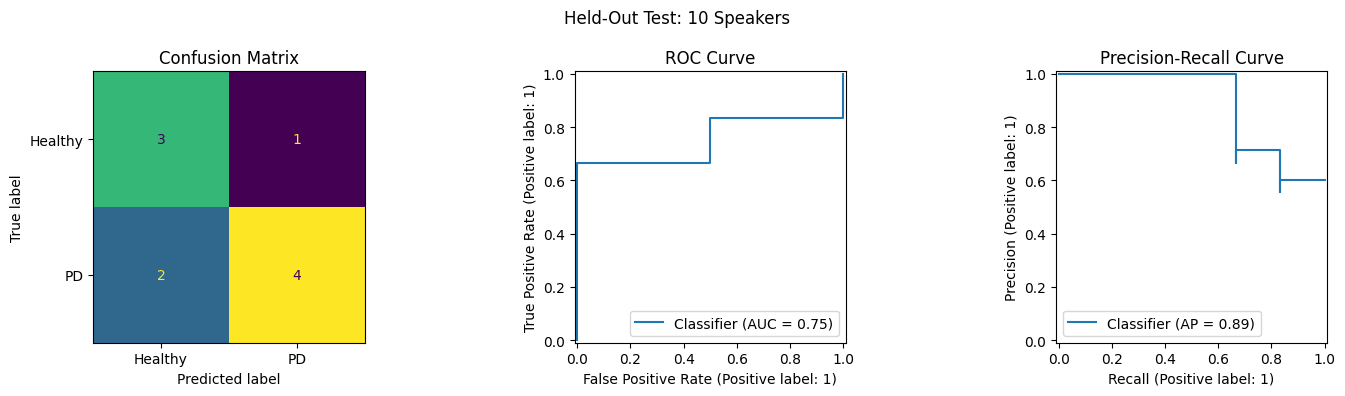

Figure saved to: /content/drive/MyDrive/PD_Acoustic_Results/test_evaluation.png


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ConfusionMatrixDisplay.from_predictions(
    test_by_speaker["label"],
    test_by_speaker["prediction"],
    display_labels=["Healthy", "PD"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Confusion Matrix")

RocCurveDisplay.from_predictions(
    test_by_speaker["label"],
    test_by_speaker["probability"],
    ax=axes[1]
)
axes[1].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(
    test_by_speaker["label"],
    test_by_speaker["probability"],
    ax=axes[2]
)
axes[2].set_title("Precision-Recall Curve")

fig.suptitle("Held-Out Test: 10 Speakers")
fig.tight_layout()
fig.savefig(OUT_DIR / "test_evaluation.png", dpi=200)
plt.show()

print("Figure saved to:", OUT_DIR / "test_evaluation.png")

In [ ]:
from scipy.stats import binomtest
from sklearn.metrics import confusion_matrix
import pandas as pd

tn, fp, fn, tp = confusion_matrix(
    test_by_speaker["label"],
    test_by_speaker["prediction"],
    labels=[0, 1]
).ravel()

counts = [
    ("Accuracy", tn + tp, tn + fp + fn + tp),
    ("PD recall", tp, tp + fn),
    ("Healthy specificity", tn, tn + fp),
]

rows = []
for metric, correct, total in counts:
    interval = binomtest(correct, total).proportion_ci(
        confidence_level=0.95,
        method="exact"
    )
    rows.append({
        "metric": metric,
        "correct": correct,
        "total": total,
        "estimate": correct / total,
        "ci_95_low": interval.low,
        "ci_95_high": interval.high
    })

uncertainty = pd.DataFrame(rows)
display(uncertainty)

uncertainty.to_csv(
    OUT_DIR / "test_uncertainty.csv",
    index=False
)

,metric,correct,total,estimate,ci_95_low,ci_95_high
0,Accuracy,7,10,0.700000,0.347547,0.933260
1,PD recall,4,6,0.666667,0.222778,0.956728
2,Healthy specificity,3,4,0.750000,0.194120,0.993691


We evaluated an acoustic-feature-based Logistic Regression model using 99 sustained /a/ vowel recordings from 50 speakers: 28 with Parkinson’s disease and 22 elderly healthy controls. Pitch, jitter, shimmer, and MFCC summary features were extracted from each recording. Speakers were separated into 40 for training and 10 for a held-out test. Model settings were selected using five-fold cross-validation within the training speakers.

On the held-out test speakers, the model achieved 70.0% accuracy, 0.727 F1-score, 0.750 AUROC, and 0.878 AUPRC. It correctly identified four of six speakers with Parkinson’s disease and three of four healthy controls. The exact 95% confidence interval for accuracy was 34.8%–93.3%, reflecting the small test group. Although training cross-validation produced stronger results, the held-out F1-score did not meet the proposed target of 0.85. These findings are preliminary and require evaluation with more independent speakers.


In [ ]:
import re
import zipfile
import pandas as pd

vowel_rows = []

with zipfile.ZipFile(LOCAL_ZIP) as z:
    for member in z.namelist():
        if not member.lower().endswith(".wav"):
            continue

        filename = member.rsplit("/", 1)[-1]
        code = filename[:3].upper()

        if not re.fullmatch(r"V[AEIOU][12]", code):
            continue

        group = member.split("/")[0]
        if group.startswith("28 People"):
            label = 1
        elif group.startswith("22 Elderly"):
            label = 0
        else:
            continue

        speaker_path = member.rsplit("/", 1)[0]
        vowel_rows.append({
            "zip_member": member,
            "speaker_id": speaker_map.get(speaker_path),
            "recording_code": code,
            "label": label
        })

vowel_manifest = pd.DataFrame(vowel_rows)

print("Vowel recordings:", len(vowel_manifest))
print("Speakers:", vowel_manifest["speaker_id"].nunique())
print("Unmatched speaker IDs:", vowel_manifest["speaker_id"].isna().sum())

display(
    pd.crosstab(
        vowel_manifest["recording_code"].str[:2],
        vowel_manifest["label"],
        rownames=["vowel"],
        colnames=["label"]
    )
)

vowel_manifest.to_csv(
    OUT_DIR / "all_vowels_manifest.csv",
    index=False
)


Vowel recordings: 495
Speakers: 50
Unmatched speaker IDs: 0


label,0,1
vowel,,
VA,44,55
VE,44,55
VI,44,55
VO,44,55
VU,44,55


In [ ]:
extra_manifest = vowel_manifest[
    vowel_manifest["recording_code"].str[:2] != "VA"
].copy()

new_rows = []
failed_rows = []

with zipfile.ZipFile(LOCAL_ZIP) as z:
    for number, row in enumerate(
        extra_manifest.itertuples(index=False), start=1
    ):
        try:
            extracted = extract_features(z.read(row.zip_member))
            new_rows.append({
                "speaker_id": row.speaker_id,
                "recording_code": row.recording_code,
                "vowel": row.recording_code[:2],
                "label": row.label,
                **extracted
            })
        except Exception as error:
            failed_rows.append({
                "speaker_id": row.speaker_id,
                "recording_code": row.recording_code,
                "error": str(error)
            })

        if number % 50 == 0:
            print(f"Processed {number} of {len(extra_manifest)} files")

extra_features = pd.DataFrame(new_rows)

original_features = features.copy()
original_features["vowel"] = original_features[
    "recording_code"
].str[:2]

all_vowel_features = pd.concat(
    [original_features, extra_features],
    ignore_index=True
)

print("Additional recordings extracted:", len(extra_features))
print("Failed recordings:", len(failed_rows))
print("All vowel recordings:", len(all_vowel_features))
print("Speakers:", all_vowel_features["speaker_id"].nunique())

display(
    pd.crosstab(
        all_vowel_features["vowel"],
        all_vowel_features["label"]
    )
)

all_vowel_features.to_csv(
    OUT_DIR / "all_vowel_features.csv",
    index=False
)
pd.DataFrame(failed_rows).to_csv(
    OUT_DIR / "all_vowel_extraction_failures.csv",
    index=False
)

Processed 50 of 396 files
Processed 100 of 396 files
Processed 150 of 396 files
Processed 200 of 396 files
Processed 250 of 396 files
Processed 300 of 396 files
Processed 350 of 396 files
Additional recordings extracted: 396
Failed recordings: 0
All vowel recordings: 495
Speakers: 50


label,0,1
vowel,,
VA,44,55
VE,44,55
VI,44,55
VO,44,55
VU,44,55


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score

multi_train = all_vowel_features[
    all_vowel_features["speaker_id"].isin(train_speakers["speaker_id"])
].copy()

model_columns = feature_cols + ["vowel"]

def make_multi_vowel_model(C):
    numeric_steps = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median", keep_empty_features=True
        )),
        ("scaler", StandardScaler())
    ])

    preprocessing = ColumnTransformer([
        ("acoustic", numeric_steps, feature_cols),
        ("vowel", OneHotEncoder(handle_unknown="ignore"), ["vowel"])
    ])

    return Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", LogisticRegression(C=C, max_iter=2000))
    ])

multi_cv_rows = []

for C in [0.01, 0.1, 1, 10]:
    fold_aurocs = []
    fold_f1s = []

    for fit_idx, val_idx in cv.split(
        train_speakers["speaker_id"],
        train_speakers["label"]
    ):
        fit_ids = set(train_speakers.iloc[fit_idx]["speaker_id"])
        val_ids = set(train_speakers.iloc[val_idx]["speaker_id"])

        fit_rows = multi_train[
            multi_train["speaker_id"].isin(fit_ids)
        ]
        val_rows = multi_train[
            multi_train["speaker_id"].isin(val_ids)
        ]

        model = make_multi_vowel_model(C)
        model.fit(fit_rows[model_columns], fit_rows["label"])

        val_predictions = val_rows[
            ["speaker_id", "label"]
        ].copy()
        val_predictions["probability"] = model.predict_proba(
            val_rows[model_columns]
        )[:, 1]

        speaker_predictions = val_predictions.groupby(
            "speaker_id", as_index=False
        ).agg(
            label=("label", "first"),
            probability=("probability", "mean")
        )
        speaker_predictions["prediction"] = (
            speaker_predictions["probability"] >= 0.5
        ).astype(int)

        fold_aurocs.append(
            roc_auc_score(
                speaker_predictions["label"],
                speaker_predictions["probability"]
            )
        )
        fold_f1s.append(
            f1_score(
                speaker_predictions["label"],
                speaker_predictions["prediction"],
                zero_division=0
            )
        )

    multi_cv_rows.append({
        "C": C,
        "mean_cv_auroc": float(np.mean(fold_aurocs)),
        "std_cv_auroc": float(np.std(fold_aurocs)),
        "mean_cv_f1": float(np.mean(fold_f1s))
    })

multi_cv_results = pd.DataFrame(multi_cv_rows).sort_values(
    ["mean_cv_auroc", "C"],
    ascending=[False, True]
)

print("Training speakers:", multi_train["speaker_id"].nunique())
print("Training recordings:", len(multi_train))
print("Previous /a/ best mean CV AUROC:",
      cv_results["mean_cv_auroc"].max())
print("Five-vowel cross-validation results:")
display(multi_cv_results)

multi_cv_results.to_csv(
    OUT_DIR / "five_vowel_cv_results.csv",
    index=False
)

Training speakers: 40
Training recordings: 395
Previous /a/ best mean CV AUROC: 0.975
Five-vowel cross-validation results:


,C,mean_cv_auroc,std_cv_auroc,mean_cv_f1
1,0.10,1.000000,0.000000,0.955556
2,1.00,1.000000,0.000000,0.955556
3,10.00,1.000000,0.000000,0.955556
0,0.01,0.973333,0.053333,0.955556


In [ ]:
import hashlib
import io
import zipfile
import soundfile as sf

audit_rows = []

with zipfile.ZipFile(LOCAL_ZIP) as z:
    for row in vowel_manifest.itertuples(index=False):
        audio_bytes = z.read(row.zip_member)
        info = sf.info(io.BytesIO(audio_bytes))

        audit_rows.append({
            "speaker_id": row.speaker_id,
            "label": row.label,
            "recording_code": row.recording_code,
            "audio_hash": hashlib.sha256(audio_bytes).hexdigest(),
            "sample_rate": info.samplerate,
            "channels": info.channels,
            "duration_seconds": info.duration
        })

audio_audit = pd.DataFrame(audit_rows)

train_ids = set(train_speakers["speaker_id"])
test_ids = set(test_speakers["speaker_id"])

cross_speaker_hashes = (
    audio_audit.groupby("audio_hash")["speaker_id"].nunique() > 1
)

print("Train/test speaker overlap:", len(train_ids & test_ids))
print("Duplicate audio shared by different speakers:",
      int(cross_speaker_hashes.sum()))
print("Unique audio files:", audio_audit["audio_hash"].nunique())

print("Sample rates by label:")
display(pd.crosstab(
    audio_audit["sample_rate"],
    audio_audit["label"]
))

print("Recording duration by label:")
display(
    audio_audit.groupby("label")["duration_seconds"]
    .agg(["count", "median", "min", "max"])
)

audio_audit.drop(columns="audio_hash").to_csv(
    OUT_DIR / "audio_quality_audit.csv",
    index=False
)

Train/test speaker overlap: 0
Duplicate audio shared by different speakers: 0
Unique audio files: 495
Sample rates by label:


label,0,1
sample_rate,,
16000,220,175
44100,0,100


Recording duration by label:


,count,median,min,max
label,,,,
0,220,7.145531,5.50275,29.312000
1,275,10.030000,3.37500,35.220431


In [ ]:
speaker_audio = audio_audit.groupby(
    ["speaker_id", "label"], as_index=False
).agg(
    sample_rates=(
        "sample_rate",
        lambda values: ", ".join(
            str(rate) for rate in sorted(set(values))
        )
    ),
    recordings=("sample_rate", "size"),
    median_duration=("duration_seconds", "median")
)

speaker_audio["split"] = np.where(
    speaker_audio["speaker_id"].isin(train_ids),
    "train",
    "test"
)

print("Speakers by split, label, and original sample rate:")
display(pd.crosstab(
    [speaker_audio["split"], speaker_audio["label"]],
    speaker_audio["sample_rates"]
))

print("Audio details for the original test speakers:")
test_audio_details = speaker_audio[
    speaker_audio["split"] == "test"
].merge(
    test_by_speaker[
        ["speaker_id", "probability", "prediction"]
    ],
    on="speaker_id"
)

display(test_audio_details.sort_values("speaker_id"))

Speakers by split, label, and original sample rate:


sample_rates  16000  44100
split label               
test  0           4      0
      1           3      3
train 0          18      0
      1          15      7

Audio details for the original test speakers:


,speaker_id,label,sample_rates,recordings,median_duration,split,probability,prediction
0,S007,0,16000,10,8.595125,test,0.763764,1
1,S011,0,16000,10,7.482219,test,0.023054,0
2,S015,0,16000,10,10.416562,test,0.219665,0
3,S020,0,16000,10,8.210969,test,0.113014,0
4,S023,1,44100,10,17.500726,test,0.997402,1
5,S024,1,44100,10,13.550726,test,0.002207,0
6,S034,1,16000,10,6.625000,test,0.156100,0
7,S043,1,16000,10,5.750000,test,0.995771,1
8,S044,1,16000,10,8.187500,test,0.996570,1
9,S047,1,44100,10,8.265000,test,0.978581,1


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

meta_train = train_speakers[
    ["speaker_id", "label"]
].merge(
    speaker_audio[
        ["speaker_id", "sample_rates", "median_duration"]
    ],
    on="speaker_id",
    validate="one_to_one"
)

meta_train["is_44100"] = (
    meta_train["sample_rates"] == "44100"
).astype(int)

control_feature_sets = {
    "sample_rate_only": ["is_44100"],
    "duration_only": ["median_duration"],
    "sample_rate_and_duration": [
        "is_44100", "median_duration"
    ]
}

control_results = []

for name, columns in control_feature_sets.items():
    fold_aurocs = []

    for fit_idx, val_idx in cv.split(
        meta_train["speaker_id"],
        meta_train["label"]
    ):
        control_model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                C=1.0, max_iter=1000
            ))
        ])

        control_model.fit(
            meta_train.iloc[fit_idx][columns],
            meta_train.iloc[fit_idx]["label"]
        )

        probabilities = control_model.predict_proba(
            meta_train.iloc[val_idx][columns]
        )[:, 1]

        fold_aurocs.append(
            roc_auc_score(
                meta_train.iloc[val_idx]["label"],
                probabilities
            )
        )

    control_results.append({
        "features": name,
        "mean_cv_auroc": np.mean(fold_aurocs),
        "std_cv_auroc": np.std(fold_aurocs)
    })

control_results = pd.DataFrame(control_results)
display(control_results)

control_results.to_csv(
    OUT_DIR / "recording_metadata_control.csv",
    index=False
)

,features,mean_cv_auroc,std_cv_auroc
0,sample_rate_only,0.650000,0.098742
1,duration_only,0.593333,0.199611
2,sample_rate_and_duration,0.530000,0.177764


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, f1_score

same_rate_ids = set(
    speaker_audio.loc[
        (speaker_audio["split"] == "train") &
        (speaker_audio["sample_rates"] == "16000"),
        "speaker_id"
    ]
)

same_rate_speakers = train_speakers[
    train_speakers["speaker_id"].isin(same_rate_ids)
].reset_index(drop=True)

same_rate_rows = multi_train[
    multi_train["speaker_id"].isin(same_rate_ids)
]

rate_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

rate_aurocs = []
rate_f1s = []

for fit_idx, val_idx in rate_cv.split(
    same_rate_speakers["speaker_id"],
    same_rate_speakers["label"]
):
    fit_ids = set(
        same_rate_speakers.iloc[fit_idx]["speaker_id"]
    )
    val_ids = set(
        same_rate_speakers.iloc[val_idx]["speaker_id"]
    )

    fit_rows = same_rate_rows[
        same_rate_rows["speaker_id"].isin(fit_ids)
    ]
    val_rows = same_rate_rows[
        same_rate_rows["speaker_id"].isin(val_ids)
    ]

    model = make_multi_vowel_model(C=0.1)
    model.fit(fit_rows[model_columns], fit_rows["label"])

    predictions = val_rows[["speaker_id", "label"]].copy()
    predictions["probability"] = model.predict_proba(
        val_rows[model_columns]
    )[:, 1]

    speaker_results = predictions.groupby(
        "speaker_id", as_index=False
    ).agg(
        label=("label", "first"),
        probability=("probability", "mean")
    )

    rate_aurocs.append(
        roc_auc_score(
            speaker_results["label"],
            speaker_results["probability"]
        )
    )
    rate_f1s.append(
        f1_score(
            speaker_results["label"],
            (speaker_results["probability"] >= 0.5).astype(int),
            zero_division=0
        )
    )

print("16 kHz training speakers:", len(same_rate_speakers))
print("Class counts:",
      same_rate_speakers["label"].value_counts().to_dict())
print("Mean CV AUROC:", np.mean(rate_aurocs))
print("AUROC by fold:", rate_aurocs)
print("Mean CV F1:", np.mean(rate_f1s))

16 kHz training speakers: 33
Class counts: {0: 18, 1: 15}
Mean CV AUROC: 1.0
AUROC by fold: [np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0)]
Mean CV F1: 0.9314285714285715


In [ ]:
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, precision_recall_curve, auc,
    confusion_matrix
)

best_multi_C = float(multi_cv_results.iloc[0]["C"])

multi_test = all_vowel_features[
    all_vowel_features["speaker_id"].isin(
        test_speakers["speaker_id"]
    )
].copy()

multi_model = make_multi_vowel_model(best_multi_C)
multi_model.fit(
    multi_train[model_columns],
    multi_train["label"]
)

multi_test["probability"] = multi_model.predict_proba(
    multi_test[model_columns]
)[:, 1]

multi_test_by_speaker = multi_test.groupby(
    "speaker_id", as_index=False
).agg(
    label=("label", "first"),
    probability=("probability", "mean"),
    recordings=("probability", "size")
)

multi_test_by_speaker["prediction"] = (
    multi_test_by_speaker["probability"] >= 0.5
).astype(int)

y_true = multi_test_by_speaker["label"]
y_prob = multi_test_by_speaker["probability"]
y_pred = multi_test_by_speaker["prediction"]

pr_precision, pr_recall, _ = precision_recall_curve(
    y_true, y_prob
)

multi_results = {
    "model": "five_vowels",
    "test_speakers": len(multi_test_by_speaker),
    "accuracy": accuracy_score(y_true, y_pred),
    "f1": f1_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred),
    "recall": recall_score(y_true, y_pred),
    "auroc": roc_auc_score(y_true, y_prob),
    "auprc": auc(pr_recall, pr_precision)
}

comparison = pd.DataFrame([
    {
        "model": "a_only",
        "accuracy": results["accuracy"],
        "f1": results["f1"],
        "auroc": results["auroc"],
        "auprc": results["auprc"]
    },
    {
        "model": "five_vowels",
        "accuracy": multi_results["accuracy"],
        "f1": multi_results["f1"],
        "auroc": multi_results["auroc"],
        "auprc": multi_results["auprc"]
    }
])

print("Selected C:", best_multi_C)
print("Five-vowel test confusion matrix [healthy, PD]:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

display(comparison)
display(multi_test_by_speaker)

comparison.to_csv(
    OUT_DIR / "exploratory_model_comparison.csv",
    index=False
)
multi_test_by_speaker.to_csv(
    OUT_DIR / "five_vowel_test_predictions.csv",
    index=False
)

Selected C: 0.1
Five-vowel test confusion matrix [healthy, PD]:
[[4 0]
 [1 5]]


,model,accuracy,f1,auroc,auprc
0,a_only,0.7,0.727273,0.750,0.878042
1,five_vowels,0.9,0.909091,0.875,0.940972


,speaker_id,label,probability,recordings,prediction
0,S007,0,0.300466,10,0
1,S011,0,0.210532,10,0
2,S015,0,0.291055,10,0
3,S020,0,0.458457,10,0
4,S023,1,0.967398,10,1
5,S024,1,0.276422,10,0
6,S034,1,0.777277,10,1
7,S043,1,0.934987,10,1
8,S044,1,0.950543,10,1
9,S047,1,0.820995,10,1


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score, f1_score, accuracy_score, confusion_matrix
)

def predict_for_speakers(C, fit_ids, predict_ids):
    fit_rows = all_vowel_features[
        all_vowel_features["speaker_id"].isin(fit_ids)
    ]
    predict_rows = all_vowel_features[
        all_vowel_features["speaker_id"].isin(predict_ids)
    ]

    current_model = make_multi_vowel_model(C)
    current_model.fit(
        fit_rows[model_columns],
        fit_rows["label"]
    )

    predictions = predict_rows[
        ["speaker_id", "label"]
    ].copy()
    predictions["probability"] = current_model.predict_proba(
        predict_rows[model_columns]
    )[:, 1]

    return predictions.groupby(
        "speaker_id", as_index=False
    ).agg(
        label=("label", "first"),
        probability=("probability", "mean")
    )


all_speakers = all_vowel_features.groupby(
    "speaker_id", as_index=False
)["label"].first()

outer_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=2026
)
inner_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=2027
)

candidate_C = [0.01, 0.1, 1, 10]
outer_predictions = []
fold_results = []

for fold_number, (development_idx, evaluation_idx) in enumerate(
    outer_cv.split(
        all_speakers["speaker_id"],
        all_speakers["label"]
    ),
    start=1
):
    development = all_speakers.iloc[
        development_idx
    ].reset_index(drop=True)
    evaluation_ids = set(
        all_speakers.iloc[evaluation_idx]["speaker_id"]
    )

    candidate_scores = {}

    for C in candidate_C:
        inner_aurocs = []

        for fit_idx, validation_idx in inner_cv.split(
            development["speaker_id"],
            development["label"]
        ):
            fit_ids = set(
                development.iloc[fit_idx]["speaker_id"]
            )
            validation_ids = set(
                development.iloc[validation_idx]["speaker_id"]
            )

            validation_predictions = predict_for_speakers(
                C, fit_ids, validation_ids
            )
            inner_aurocs.append(
                roc_auc_score(
                    validation_predictions["label"],
                    validation_predictions["probability"]
                )
            )

        candidate_scores[C] = np.mean(inner_aurocs)

    selected_C = sorted(
        candidate_C,
        key=lambda C: (-candidate_scores[C], C)
    )[0]

    evaluation_predictions = predict_for_speakers(
        selected_C,
        set(development["speaker_id"]),
        evaluation_ids
    )
    evaluation_predictions["fold"] = fold_number
    evaluation_predictions["selected_C"] = selected_C
    evaluation_predictions["prediction"] = (
        evaluation_predictions["probability"] >= 0.5
    ).astype(int)

    outer_predictions.append(evaluation_predictions)
    fold_results.append({
        "fold": fold_number,
        "selected_C": selected_C,
        "auroc": roc_auc_score(
            evaluation_predictions["label"],
            evaluation_predictions["probability"]
        ),
        "f1": f1_score(
            evaluation_predictions["label"],
            evaluation_predictions["prediction"]
        )
    })

nested_oof = pd.concat(
    outer_predictions, ignore_index=True
)
nested_folds = pd.DataFrame(fold_results)

print("Evaluated speakers:", nested_oof["speaker_id"].nunique())
print("Pooled AUROC:", roc_auc_score(
    nested_oof["label"], nested_oof["probability"]
))
print("Pooled F1:", f1_score(
    nested_oof["label"], nested_oof["prediction"]
))
print("Pooled accuracy:", accuracy_score(
    nested_oof["label"], nested_oof["prediction"]
))
print("Confusion matrix [healthy, PD]:")
print(confusion_matrix(
    nested_oof["label"],
    nested_oof["prediction"],
    labels=[0, 1]
))
print("Results by outer fold:")
display(nested_folds)

nested_oof.to_csv(
    OUT_DIR / "five_vowel_nested_oof_predictions.csv",
    index=False
)
nested_folds.to_csv(
    OUT_DIR / "five_vowel_nested_fold_results.csv",
    index=False
)

Evaluated speakers: 50
Pooled AUROC: 0.987012987012987
Pooled F1: 0.9473684210526315
Pooled accuracy: 0.94
Confusion matrix [healthy, PD]:
[[20  2]
 [ 1 27]]
Results by outer fold:


,fold,selected_C,auroc,f1
0,1,1,1.000000,0.833333
1,2,1,1.000000,1.000000
2,3,10,0.958333,0.909091
3,4,1,1.000000,1.000000
4,5,1,1.000000,1.000000


In [ ]:
import joblib
import json
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

selection_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

selection_rows = []

for C in [0.01, 0.1, 1, 10]:
    fold_aurocs = []

    for fit_idx, val_idx in selection_cv.split(
        all_speakers["speaker_id"],
        all_speakers["label"]
    ):
        fit_ids = set(all_speakers.iloc[fit_idx]["speaker_id"])
        val_ids = set(all_speakers.iloc[val_idx]["speaker_id"])

        predictions = predict_for_speakers(
            C, fit_ids, val_ids
        )
        fold_aurocs.append(
            roc_auc_score(
                predictions["label"],
                predictions["probability"]
            )
        )

    selection_rows.append({
        "C": C,
        "mean_cv_auroc": float(np.mean(fold_aurocs))
    })

final_selection = pd.DataFrame(selection_rows).sort_values(
    ["mean_cv_auroc", "C"],
    ascending=[False, True]
)

final_C = float(final_selection.iloc[0]["C"])
final_model = make_multi_vowel_model(final_C)
final_model.fit(
    all_vowel_features[model_columns],
    all_vowel_features["label"]
)

model_path = OUT_DIR / "five_vowel_final_model.joblib"
joblib.dump(final_model, model_path)

model_info = {
    "model": "Acoustic features and Logistic Regression",
    "vowels": ["a", "e", "i", "o", "u"],
    "speakers_used_for_final_training": 50,
    "recordings_used_for_final_training": 495,
    "selected_C": final_C,
    "input_columns": model_columns,
    "speaker_probability": "Mean of recording probabilities"
}

with open(OUT_DIR / "five_vowel_model_info.json", "w") as file:
    json.dump(model_info, file, indent=2)

print("Final C selection:")
display(final_selection)
print("Selected C:", final_C)
print("Model saved to:", model_path)

Final C selection:


,C,mean_cv_auroc
1,0.10,1.000
2,1.00,1.000
3,10.00,1.000
0,0.01,0.975


Selected C: 0.1
Model saved to: /content/drive/MyDrive/PD_Acoustic_Results/five_vowel_final_model.joblib


### Results and Discussion

We evaluated an acoustic-feature-based Logistic Regression model using sustained recordings of five vowels (/a/, /e/, /i/, /o/, /u/) from the Italian Parkinson’s Voice and Speech dataset. The selected subset contained 495 recordings from 50 speakers: 28 with Parkinson’s disease and 22 elderly healthy controls. We extracted pitch, jitter, shimmer, and MFCC summary features from each recording. All recordings from a speaker remained in the same data split, and recording-level probabilities were averaged to produce one prediction per speaker.

In an exploratory comparison on the same 10 held-out speakers, the five-vowel model improved AUROC from 0.750 for the /a/-only model to 0.875. F1-score increased from 0.727 to 0.909, and accuracy increased from 70% to 90%. The five-vowel model correctly identified five of six speakers with Parkinson’s disease and all four healthy controls. Its AUROC exceeded the project’s target of 0.85 in this comparison.

We also performed five-fold nested cross-validation across all 50 speakers, selecting the Logistic Regression parameter within each training fold. The pooled out-of-fold AUROC was 0.987, with an F1-score of 0.947 and accuracy of 94% (47 of 50 speakers correctly classified). No speaker overlap or duplicate audio was found across the evaluated folds. These results support the five-vowel approach within this dataset, but they do not establish performance on an independent population. The five-vowel approach was chosen after inspection of the earlier held-out results, and the dataset contains only 50 speakers. Recording conditions may also differ between groups. Evaluation on new, independent speakers is needed before claiming that the AUROC target generalizes.

তোমার **পাঁচ vowel model-এর ১০ জনের test result** হলো:

| Metric | Value |
|---|---:|
| **F1-score** | **0.909** (90.9%) |
| **AUROC** | **0.875** (87.5%) |
| **AUPRC** | **0.941** (94.1%) |

কেন এই মানগুলো এসেছে:

- **F1 = 0.909:** ৬ জন PD speaker-এর মধ্যে ৫ জনকে ঠিক ধরেছে, ১ জনকে বাদ দিয়েছে। যাদের PD বলেছে, তারা সবাই সত্যিই PD—কোনো healthy speaker-কে ভুল করে PD বলেনি। তাই precision 100%, recall 83.3%; এই দুটির সমন্বয়ে F1 90.9%।
- **AUROC = 0.875:** একজন PD ও একজন healthy speaker-কে জোড়া করে তুলনা করলে মোট ২৪টি জোড়া হয়। Model **২১টিতে PD speaker-কে বেশি probability** দিয়েছে। তাই AUROC `21 ÷ 24 = 0.875`।
- **AUPRC = 0.941:** বেশি probability পাওয়া speaker-দের মধ্যে PD speaker-রা বেশির ভাগই ওপরের দিকে ছিল। বিভিন্ন decision threshold-এ precision ও recall মিলিয়ে এই score এসেছে।

তোমাদের **AUROC > 0.85 লক্ষ্য এই ১০ জনের পরীক্ষায় সংখ্যাগতভাবে পূরণ হয়েছে**। তবে পাঁচ vowel পদ্ধতিটি আগের test ফল দেখার পরে বেছে নেওয়া হয়েছিল, তাই এটিকে *exploratory test result* বলতে হবে।

আর **nested CV**-তে ৫০ জনের ওপর AUROC **0.987** ও F1 **0.947** এসেছে; সেখানে AUPRC হিসাব করা হয়নি। সব ৫০ জন দিয়ে সংরক্ষিত final model-এর জন্য নতুন speaker-এর test score এখনো নেই।